In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/data.yaml
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0080_JPG_jpg.rf.5a1e133efd45c0076e6132de4393e98a.jpg
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0096_jpg.rf.89bc2c4e5eaaa11d7a6026a92d12657d.jpg
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0104_jpg.rf.4201ab1360ebc219ae384f7d26c0deec.jpg
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0113_jpg.rf.acda93150b513095554ea5ddcc5d2f54.jpg
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0117_jpg.rf.bf4a3c26430852448ba9169347e6e5cc.jpg
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0135_jpg.rf.8ecf3014342feffd4cbfb7437bddc858.jpg
/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/0137_jpg.rf.9618457c0c7557fd38b39ab94dfb6322.jpg
/kaggle/input/datasets/cubeai/f

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model = YOLO('yolo11n.pt')

In [27]:
import random
import matplotlib.pyplot as plt
import cv2

# 定义训练图片的目录路径
train_img_dir = '/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/train/images'

def pref_images_show(images = train_img_dir, num_samples = 16):
    """
    显示预测的图片

    从指定的图片目录中随机选择一定数量的样本图片，并显示这些图片的预测结果

    参数：
    images (str): 图片目录路径。默认为训练图片目录
    num_sample (int): 要显示的样本图片数量。默认为 16

    返回：
    无
    """
    # 获取图片目录中的所有图片文件名
    image_files = os.listdir(images)
    # 随机选择指定数量的图片文件
    rand_image = random.sample(image_files, num_samples)

    # 创建一个 4 * 4 的图布局，用于显示图片
    fig, axes = plt.subplots(4, 4, figsize = (16, 16))
    # 遍历每个样本图片
    for i in range(num_samples):
        # 获取当前图片文件名
        image = rand_image[i]
        # 确定当前图片在图布局中的位置
        ax = axes[i // 4, i % 4]
        # 使用模型对当前图片进行预测
        result_predict = model.predict(source = os.path.join(images, image))
        # 将预测结果的图片显示在子图中
        ax.imshow(cv2.cvtColor(result_predict[0].plot(), cv2.COLOR_BGR2RGB))
        # 设置子图的标题
        ax.set_title(f"Image {i + 1}")
        # 关闭子图的坐标轴
        ax.axis('off')

    # 调整图布局，使其紧凑
    plt.tight_layout()
    # 显示图片
    plt.show()


image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/train/images/fire1-342-_jpg.rf.00e7c7da5358cc8a37546d9c9ac9b6b8.jpg: 640x640 (no detections), 11.5ms
Speed: 1.5ms preprocess, 11.5ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/train/images/Img_1258_jpg.rf.ee001f89a02b1ea2030903bb92c3ff47.jpg: 640x640 (no detections), 11.5ms
Speed: 1.4ms preprocess, 11.5ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/train/images/WEBSmoke1072_jpg.rf.d38cd6219102c1ee283f16ff0c41f183.jpg: 640x640 (no detections), 11.6ms
Speed: 1.5ms preprocess, 11.6ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/train/images/NoiseWEBSmoke709_jpg.rf.eca9bbded8523c696c9875fe3826d99c.jpg: 640x640 (no detections)

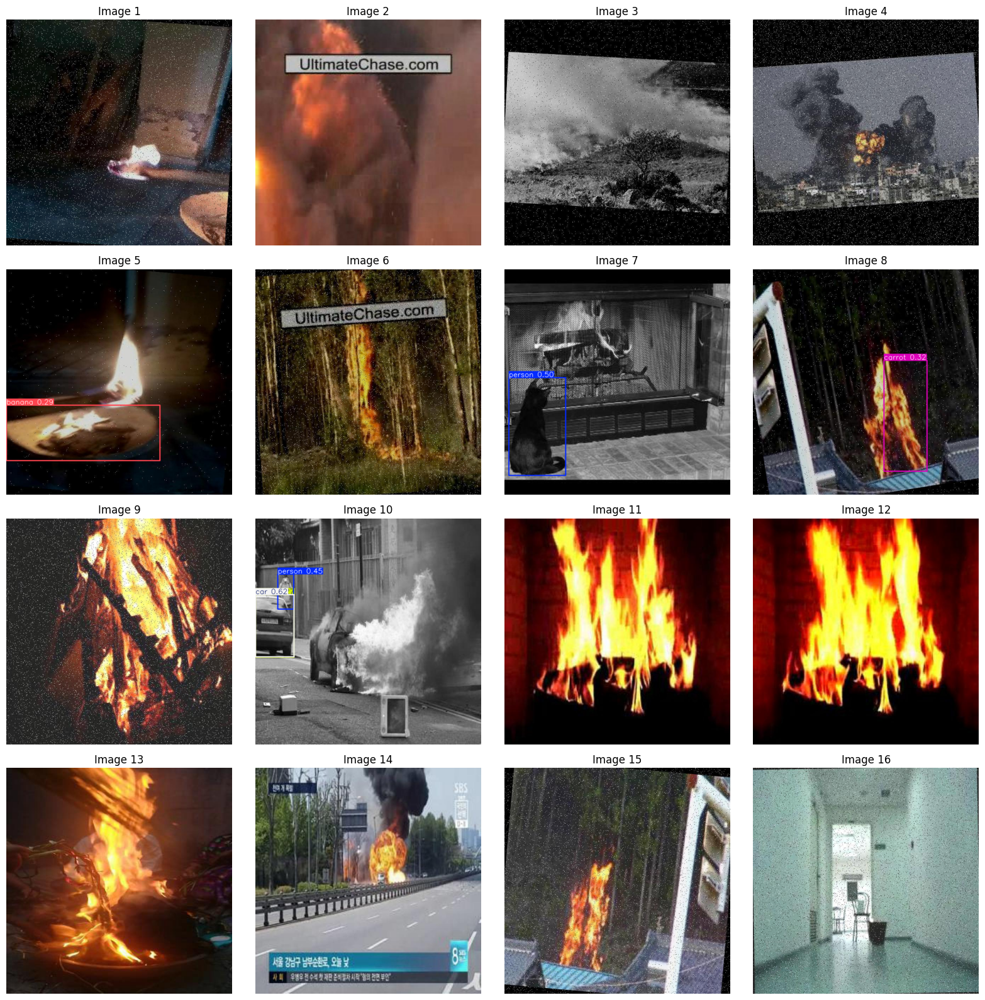

In [16]:
# 调用函数显示预测图片
pref_images_show()

In [17]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/data.yaml \
    epochs = 30 \
    imgsz = 640 \
    batch = 128 \
    device = 0,1

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=128, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

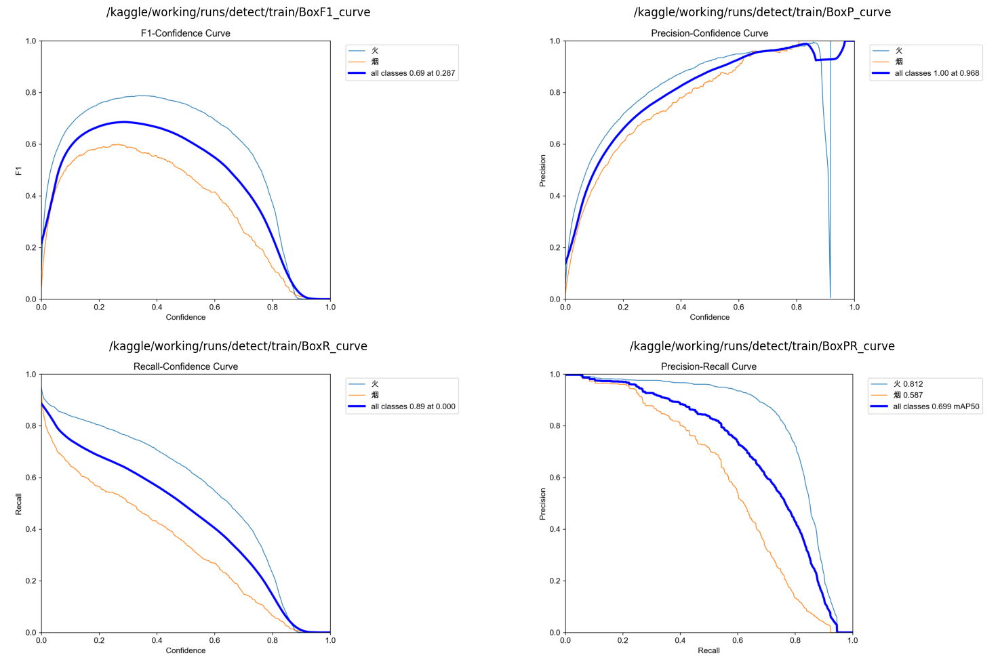

In [18]:
# 指定性能评估曲线的图片所在的目录
directory = '/kaggle/working/runs/detect/train'

# 定义要展示的图片的文件名
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

# 创建一个包含 4 张子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便于索引

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_path)[0]) # 设置子图标题为图片文件名（去掉扩展名）
        ax.axis('off')
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

# 调整子图间距
plt.tight_layout()
plt.show()

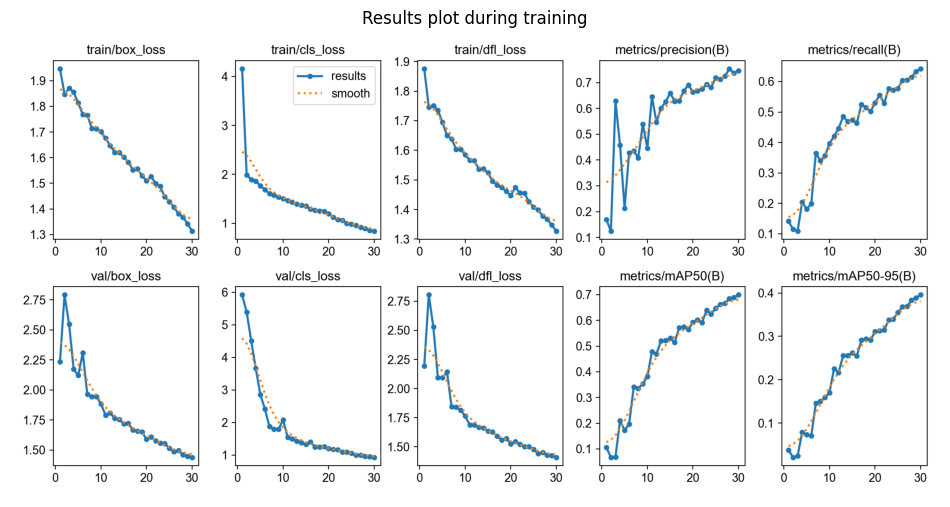

In [19]:
# results.png 图片路径
image_path = '/kaggle/working/runs/detect/train/results.png'

# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并展示
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title("Results plot during training")
plt.axis('off')
plt.show()

In [20]:
# 加载训练好的最优模型
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
# 模型验证
metrics = model.val(
    data = '/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/data.yaml'
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 172.2±66.9 MB/s, size: 97.1 KB)
val: Scanning /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/valid/labels... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 847.4it/s 2.4s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/valid is not writable, cache not saved.
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 4312. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 6.0it/s 20.7s0.2s
                   all    

In [21]:
%matplotlib inline

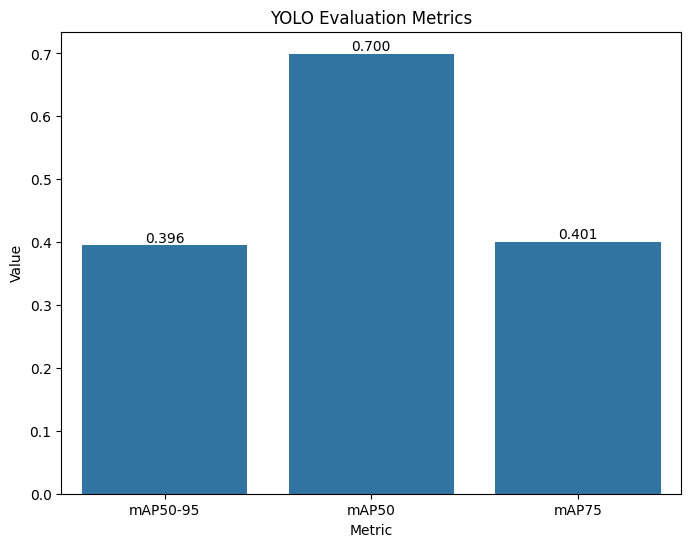

In [24]:
import seaborn as sns 

# 创建柱状图
ax = sns.barplot(
    x = ['mAP50-95', 'mAP50', 'mAP75'],
    y = [metrics.box.map, metrics.box.map50, metrics.box.map75]
)
# 设置标题和轴标签
ax.set_title('YOLO Evaluation Metrics')
ax.set_xlabel('Metric')
ax.set_ylabel('Value')
fig = plt.gcf()
fig.set_size_inches(8, 6)
# 在柱状图上方添加数值
for p in ax.patches:
    ax.annotate(
        '{:.3f}'.format(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha = 'center', va = 'bottom'
    )
# 显示图形
plt.show()


image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/Img_492_jpg.rf.809aa987e7d78d4e0c0ad2d39f1a221d.jpg: 640x640 1 火, 11.3ms
Speed: 1.5ms preprocess, 11.3ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/NoiseWEBSmoke1221_jpg.rf.b0b1a7341a06296d92ae0d99ff00ad84.jpg: 640x640 2 火s, 2 烟s, 11.4ms
Speed: 1.5ms preprocess, 11.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/497_jpg.rf.d34fcdb7b35675a2a4e9fa9e55767203.jpg: 640x640 2 火s, 11.4ms
Speed: 1.6ms preprocess, 11.4ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images/ck0tyv5y2wpox0721volr4z26_jpeg_jpg.rf.3841f8dcae4b923900ccc285588ff78d.jpg: 640x640 1 烟, 11.5ms
Speed: 1.2ms preprocess,

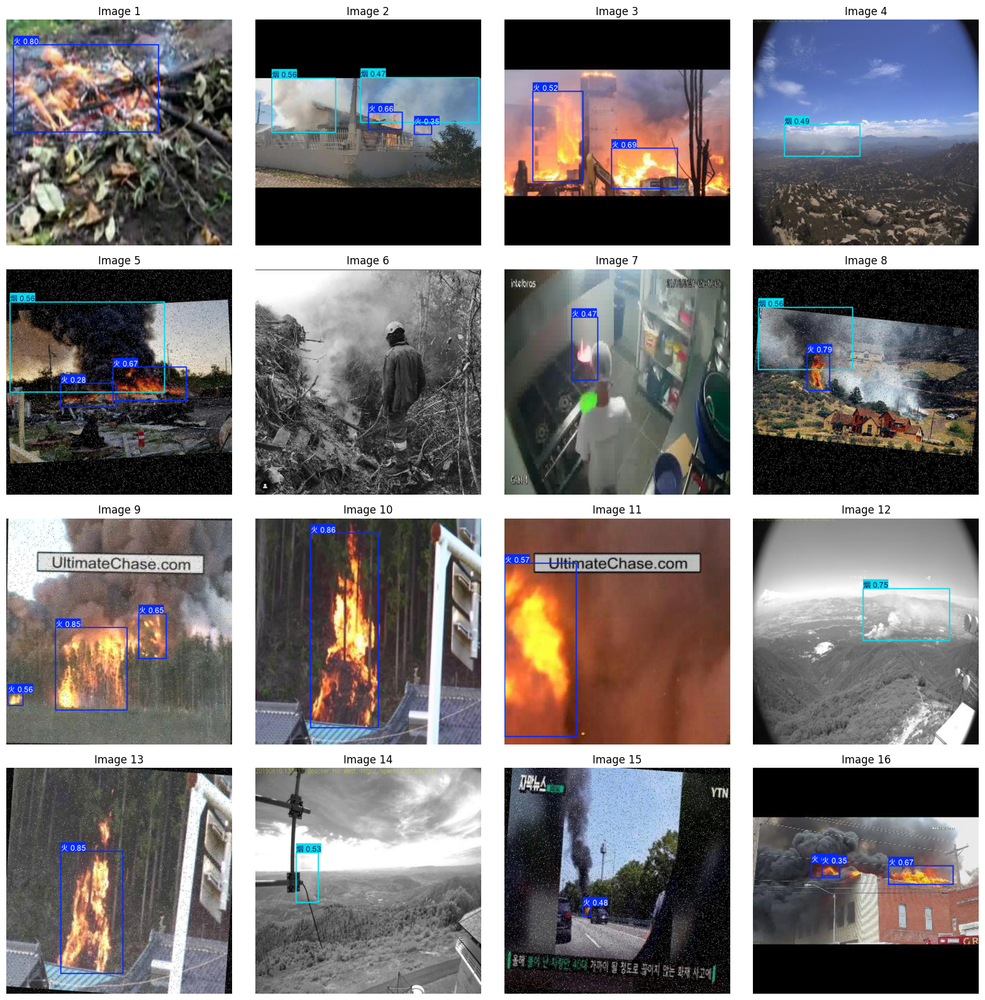

In [28]:
# 训练好的最优模型
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
test_img_dir = '/kaggle/input/datasets/cubeai/fire-and-smoke-detection-for-yolov8/test/images'
# 随机对 16 张测试集中的图片进行预测
pref_images_show(images = test_img_dir)

In [29]:
from IPython.display import display, FileLinks
display(FileLinks('./')) # 显示当前目录下所有文件的下载链接

./
  yolo11n.pt
./.virtual_documents/
  __notebook_source__.ipynb
./runs/detect/train/
  args.yaml
  confusion_matrix_normalized.png
  val_batch1_pred.jpg
  labels.jpg
  val_batch0_pred.jpg
  BoxPR_curve.png
  train_batch1102.jpg
  train_batch1.jpg
  BoxP_curve.png
  confusion_matrix.png
  train_batch1100.jpg
  results.png
  results.csv
  BoxR_curve.png
  train_batch1101.jpg
  val_batch2_labels.jpg
  BoxF1_curve.png
  val_batch0_labels.jpg
  val_batch1_labels.jpg
  train_batch0.jpg
  train_batch2.jpg
  val_batch2_pred.jpg
./runs/detect/train/weights/
  last.pt
  best.pt
./runs/detect/val/
  confusion_matrix_normalized.png
  val_batch1_pred.jpg
  val_batch0_pred.jpg
  BoxPR_curve.png
  BoxP_curve.png
  confusion_matrix.png
  BoxR_curve.png
  val_batch2_labels.jpg
  BoxF1_curve.png
  val_batch0_labels.jpg
  val_batch1_labels.jpg
  val_batch2_pred.jpg

In [30]:
!zip -q -r results.zip /kaggle/working/*